# Fitting template over a grid of $(w_0, w_a)$ backgrounds

For every background the same three steps as in `fit_LCDM` / `fit_w0wa` are applied:
1. each $(c_K, c_B)$ spectrum with the template model $\to a, b, s$
2. each parameter linearly in $c_B$: $p = m(c_K)\, c_B + y_0(c_K)$
3. $m$ and $y_0$ averaged over $c_K$ (simple mean, error = scatter$/\sqrt{N}$)

and the results are shown as maps over $(w_0, w_a)$.

Models (`MODEL`):
- `'tanh_kBkJ'`: $a \tanh\left[s\,\frac{\log_{10}(k/\sqrt{k_B k_J})}{\log_{10}(k_B/k_J)}\right] + b$
- `'tanh_kB'`: $a \tanh\left[2\log_{10}(s\,k/k_B)\right] + b$

Spectra computed with `scripts/compute_spectra.py` (`NAME = 'fit_DE_grid'`).

In [91]:
%reload_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

from dataclasses import asdict

from hiclass_tools import load_spectra_group, fit_backgrounds, MODELS, Template
from hiclass_tools.plotting import use_style, ColorScale

use_style(fontsize=12)

In [92]:
# Configuration
SPECTRA = 'fit_DE_grid'
MODEL = 'tanh_kB'            # 'tanh_kBkJ' | 'tanh_kB'
K_MIN = 3e-3                 # lower k limit of the fit [h/Mpc] (None: whole range)

sets = load_spectra_group(SPECTRA)    # {(w0, wa): SpectraSet}
model = MODELS[MODEL]
params = model.params
cK = np.unique(np.concatenate([s.cK for s in sets.values()]))   # union over backgrounds
cB = np.unique(np.concatenate([s.cB for s in sets.values()]))
k = next(iter(sets.values())).k

print(f"{len(sets)} backgrounds: w0 in [{min(w0 for w0, _ in sets):.3g}, {max(w0 for w0, _ in sets):.3g}], "
      f"wa in [{min(wa for _, wa in sets):.3g}, {max(wa for _, wa in sets):.3g}]")
print(f"cK: {len(cK)} values in [{cK[0]:.3g}, {cK[-1]:.3g}]")
print(f"cB: {len(cB)} values in [{cB[0]:.3g}, {cB[-1]:.3g}]")
print(f"k:  {len(k)} values in [{k[0]:.3g}, {k[-1]:.3g}] h/Mpc")
print(f"Failed in CLASS (unstable models): {sum(len(s.failed) for s in sets.values())}")

100 backgrounds: w0 in [-1, -0.7], wa in [-1, 0]
cK: 10 values in [1e+03, 1e+06]
cB: 10 values in [0.5, 1.5]
k:  50 values in [0.001, 10] h/Mpc
Failed in CLASS (unstable models): 70


In [93]:
fits = fit_backgrounds(sets, model=MODEL, k_min=K_MIN)   # {(w0, wa): TemplateFit}

w0_arr = np.array([w0 for w0, _ in fits])
wa_arr = np.array([wa for _, wa in fits])

# Mean error of the individual spectrum fits, per background
err_arr = np.array([f.mean_error for f in fits.values()]) * 100

print(f"Successful backgrounds: {len(fits)} / {len(sets)}")
print(f"Spectrum-fit error: {err_arr.min():.2f} - {err_arr.max():.2f} %")

# Backgrounds where CLASS rejected some (cK, cB) models as unstable: fitted with fewer cB values
unstable = np.array([(w0, wa) for (w0, wa), s in sets.items() if s.failed]).reshape(-1, 2)
print(f"Backgrounds with unstable models: {len(unstable)}")

def mark_unstable(ax, label=True):
    ax.scatter(unstable[:,0], unstable[:,1], marker='x', s=80, c='r', linewidths=2, clip_on=False, zorder=5,
               label=r'Unstable models (fewer $c_B$)' if label else None)

Successful backgrounds: 100 / 100
Spectrum-fit error: 2.83 - 4.44 %
Backgrounds with unstable models: 7


## Fitting error

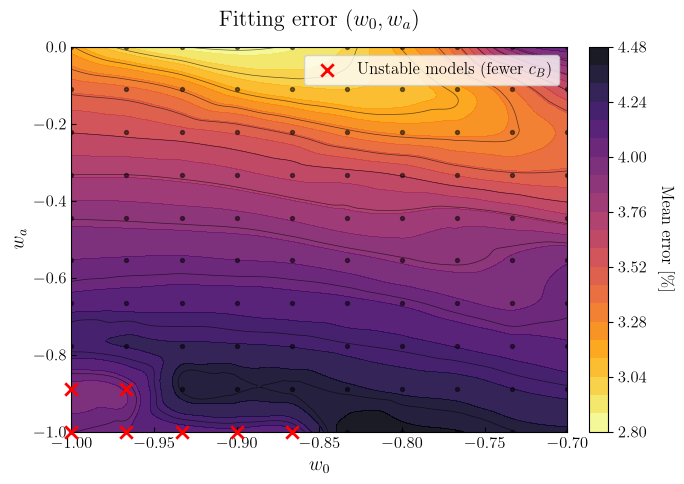

In [94]:
W0, WA = np.meshgrid(np.linspace(w0_arr.min(), w0_arr.max(), 150), np.linspace(wa_arr.min(), wa_arr.max(), 150))
Z_err = griddata((w0_arr, wa_arr), err_arr, (W0, WA), method='cubic')

fig, ax = plt.subplots(figsize=(7, 5))
contour = ax.contourf(W0, WA, Z_err, levels=25, cmap='inferno_r', alpha=0.9)
ax.contour(W0, WA, Z_err, levels=12, colors='k', linewidths=0.5, alpha=0.6)
ax.scatter(w0_arr, wa_arr, s=8, c='k', alpha=0.5)
mark_unstable(ax)

cbar = plt.colorbar(contour, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label(r'Mean error [\%]', rotation=270, labelpad=20, fontsize=12)

ax.set_title(r'Fitting error ($w_0 , w_a$)', fontsize=16, pad=15)
ax.set_xlabel(r'$w_0$', fontsize=14)
ax.set_ylabel(r'$w_a$', fontsize=14)
ax.legend(loc='upper right')
ax.tick_params(axis='both', which='both', direction='in')

## Precision of the linear fit in $c_B$

Mean $R^2$ (over $c_K$) of the linear fit $p = m\,c_B + y_0$ of each parameter, per background.

Text(0.5, 0.99, 'Linear fit precision $R^2$ for ($w_0, w_a$)')

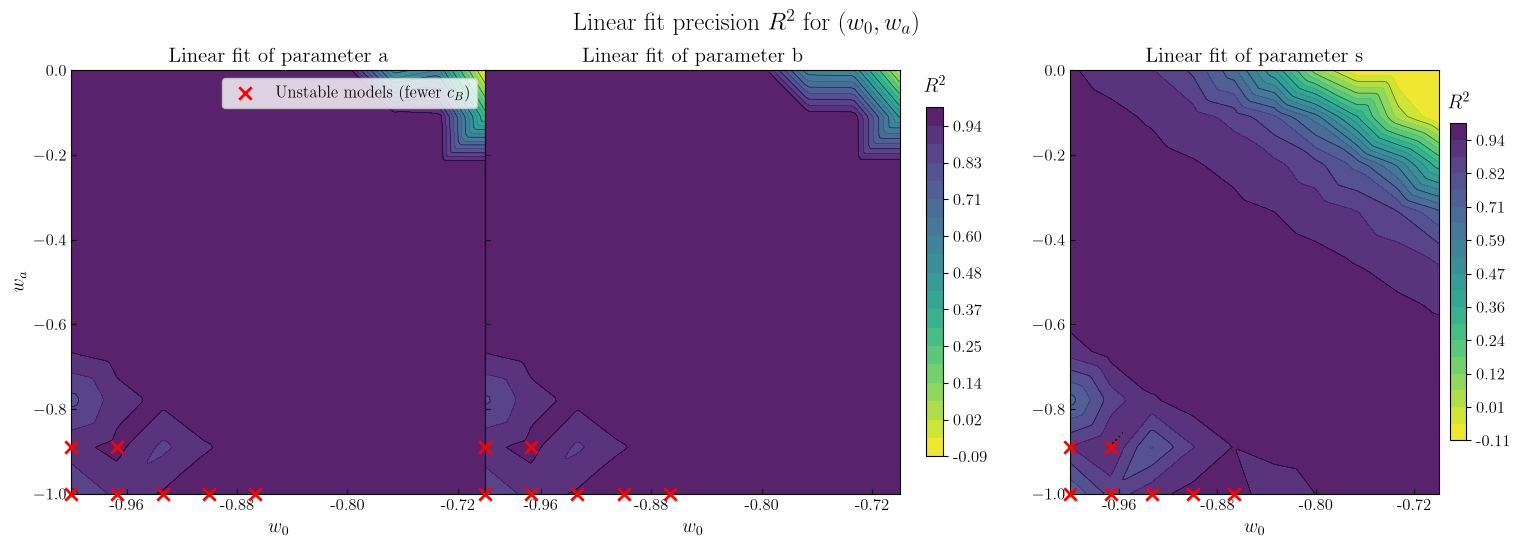

In [95]:
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

W0, WA = np.meshgrid(np.linspace(w0_arr.min(), w0_arr.max(), 120), np.linspace(wa_arr.min(), wa_arr.max(), 120))
r2 = {p: np.array([f.mean_r2(p) for f in fits.values()]) for p in params}

# a and b side by side (no space, common colour scale); s in its own panel
fig = plt.figure(figsize=(18, 5.5))
gs = fig.add_gridspec(1, 2, width_ratios=[2.2, 1], wspace=0.2)
gs_ab = gs[0].subgridspec(1, 2, wspace=0)
ax_a = fig.add_subplot(gs_ab[0])
ax_b = fig.add_subplot(gs_ab[1], sharey=ax_a)
ax_s = fig.add_subplot(gs[1], sharey=ax_a)

def r2_map(ax, values, levels):
    ok = np.isfinite(values)
    Z = griddata((w0_arr[ok], wa_arr[ok]), values[ok], (W0, WA), method='linear')
    contour = ax.contourf(W0, WA, Z, levels=levels, cmap='viridis_r', alpha=0.9)
    ax.contour(W0, WA, Z, levels=levels[::2], colors='k', linewidths=0.5, alpha=0.5)
    mark_unstable(ax, label=(ax is ax_a))
    ax.set_xlabel(r'$w_0$', fontsize=14)
    ax.tick_params(axis='both', which='both', direction='in')
    return contour

ab_values = np.concatenate([r2['a'], r2['b']])
levels_ab = np.linspace(np.nanmin(ab_values), np.nanmax(ab_values), 20)
contour_ab = r2_map(ax_a, r2['a'], levels_ab)
r2_map(ax_b, r2['b'], levels_ab)
contour_s = r2_map(ax_s, r2['s'], np.linspace(np.nanmin(r2['s']), np.nanmax(r2['s']), 20))

ax_b.tick_params(axis='y', labelleft=False)
for ax in [ax_a, ax_b, ax_s]:
    ax.xaxis.set_major_locator(MaxNLocator(5, prune='upper' if ax is ax_a else None))   # no overlap at the a|b junction
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
ax_a.set_ylabel(r'$w_a$', fontsize=14)
ax_a.legend(loc='upper right')
for ax, p in [(ax_a, 'a'), (ax_b, 'b'), (ax_s, 's')]:
    ax.set_title(f"Linear fit of parameter {p}", fontsize=15)

for contour, axes in [(contour_ab, [ax_a, ax_b]), (contour_s, [ax_s])]:
    cbar = plt.colorbar(contour, ax=axes, fraction=0.04 if len(axes) == 1 else 0.02, pad=0.03, format='%.2f')
    cbar.ax.set_title(r'$R^2$', y=1.02)

fig.suptitle(r'Linear fit precision $R^2$ for ($w_0, w_a$)', fontsize=18, y=0.99)

## Template parameters: $p = m\, c_B + y_0$

Text(0.5, 0.92, 'Modified Gravity Fit Parameters')

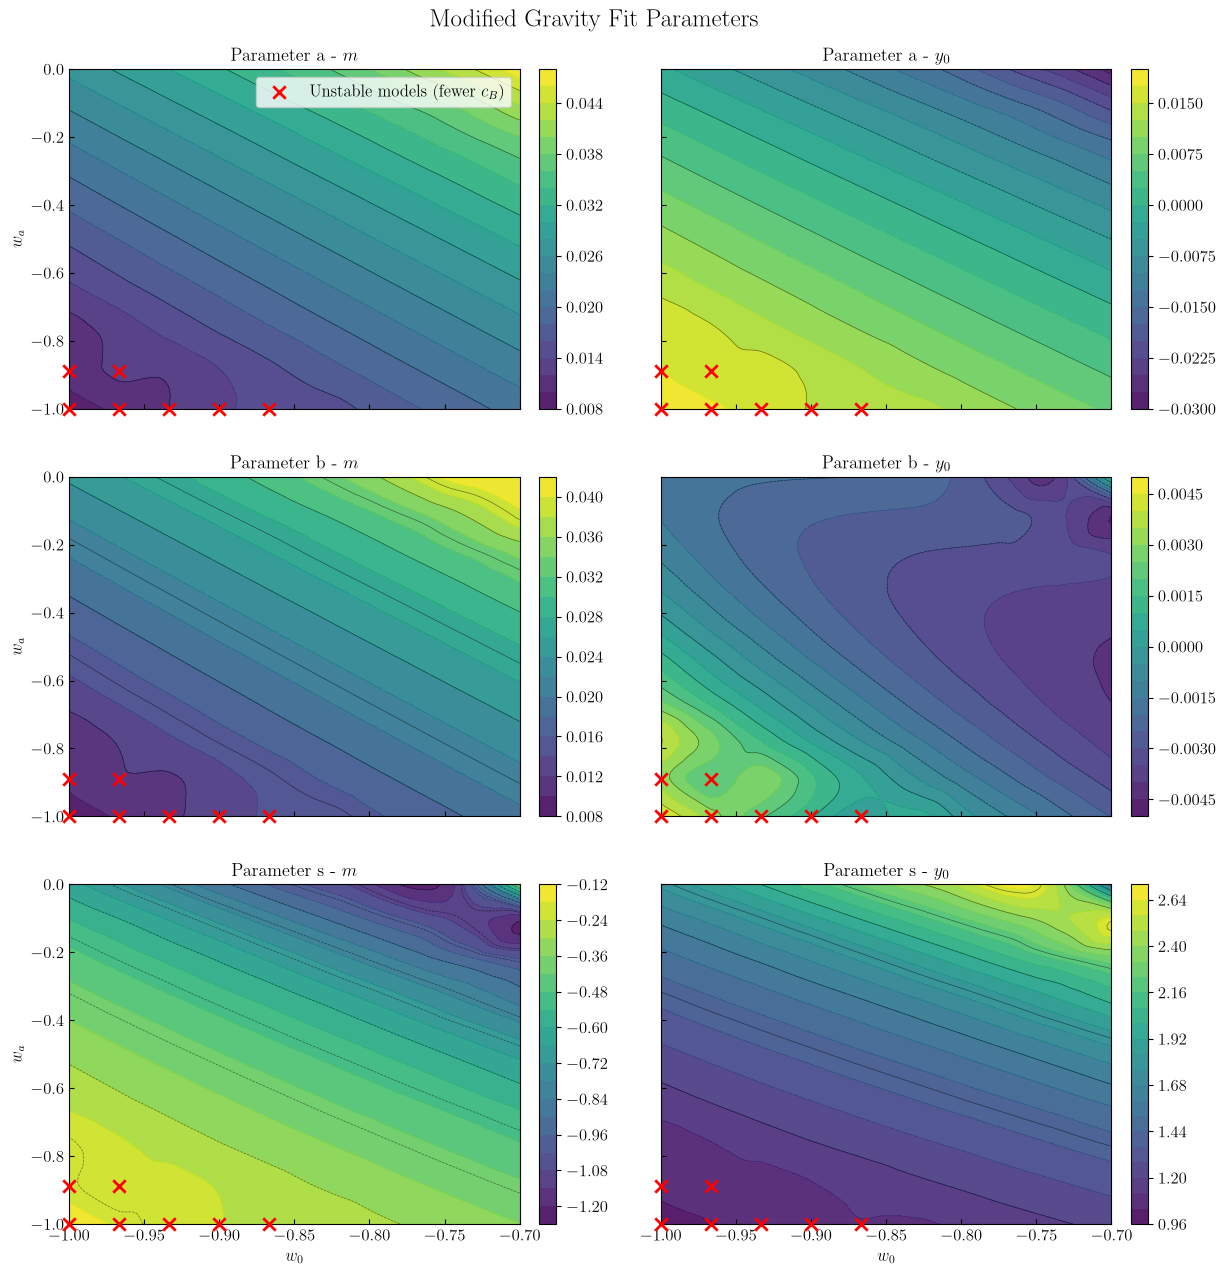

In [96]:
fig, axs = plt.subplots(len(params), 2, figsize=(14, 5*len(params)), sharex=True, sharey=True)
W0, WA = np.meshgrid(np.linspace(w0_arr.min(), w0_arr.max(), 100), np.linspace(wa_arr.min(), wa_arr.max(), 100))

for i, p in enumerate(params):
    for j, (q, q_label) in enumerate([('m', '$m$'), ('y0', '$y_0$')]):
        ax = axs[i,j]
        values = np.array([f.ck_fits[p][q].value for f in fits.values()])
        Z = griddata((w0_arr, wa_arr), values, (W0, WA), method='cubic')

        contour = ax.contourf(W0, WA, Z, levels=20, cmap='viridis', alpha=0.9)
        ax.contour(W0, WA, Z, levels=10, colors='k', linewidths=0.5, alpha=0.5)
        plt.colorbar(contour, ax=ax, fraction=0.046, pad=0.04)
        mark_unstable(ax)

        ax.set_title(f"Parameter {p} - {q_label}", fontsize=13)
        ax.tick_params(axis='both', which='both', direction='in')

for ax in axs[-1,:]: ax.set_xlabel(r'$w_0$')
for ax in axs[:,0]: ax.set_ylabel(r'$w_a$')
axs[0,0].legend(loc='upper right')
fig.suptitle('Modified Gravity Fit Parameters', fontsize=18, y=0.92)

## Dependence on $w_0 + w_a$

The contours of the parameter maps run along the diagonal, which suggests that the coefficients depend
mainly on $w_0 + w_a$ (the equation of state at early times, $w(a \to 0)$). Each coefficient is plotted
against $w_0 + w_a$, coloured by $w_0$: if the points collapse onto a single curve, $w_0$ and $w_a$ only
enter through their sum. $R^2$ of a linear fit in $w_0 + w_a$ quantifies it ($R^2 = 1$: perfect collapse).

Text(0.5, 1.0, '$w_0$')

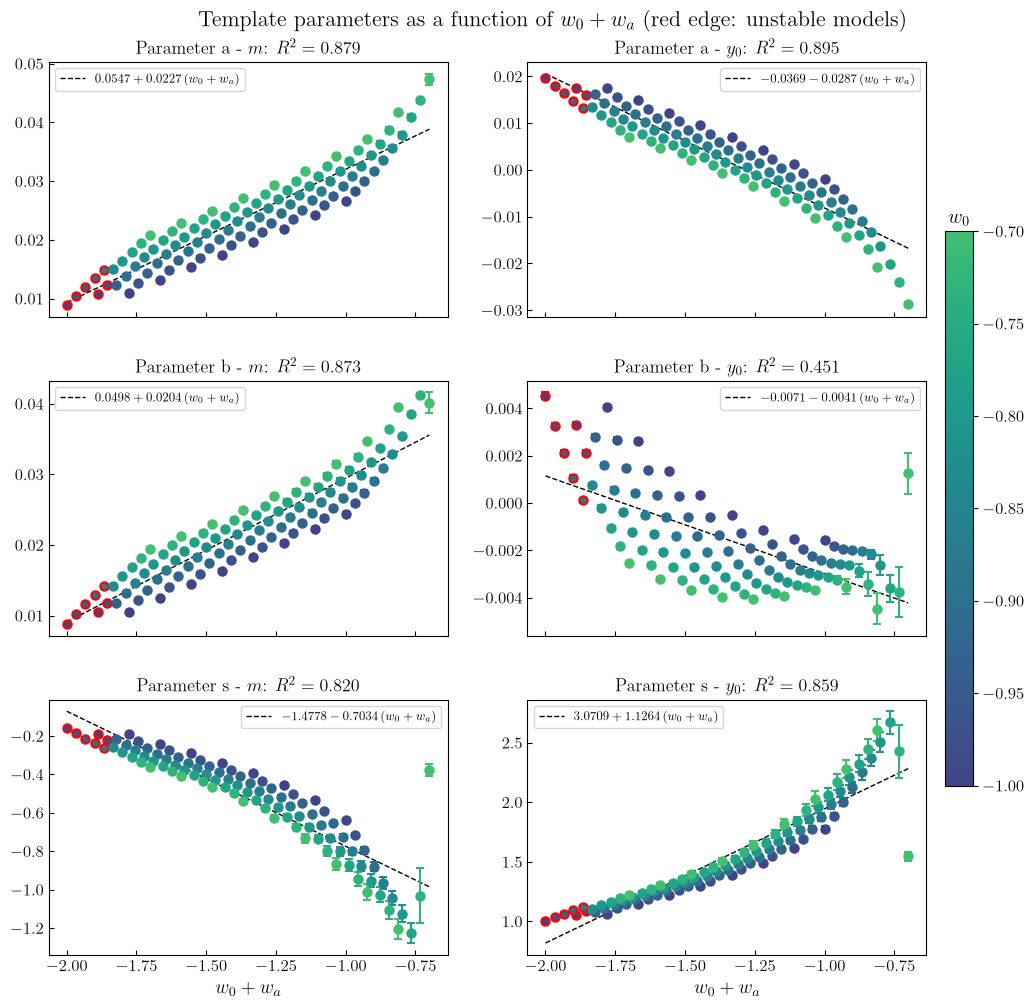

In [97]:
x = w0_arr + wa_arr
x_line = np.linspace(x.min(), x.max(), 100)
w0_colors = ColorScale(w0_arr, 'viridis')
is_unstable = np.array([(w0, wa) in set(map(tuple, unstable)) for w0, wa in zip(w0_arr, wa_arr)])

global_coeffs = {p: {} for p in params}   # p -> {'m': (alpha, beta), 'y0': (alpha, beta)}

fig, axs = plt.subplots(len(params), 2, figsize=(12, 3.5*len(params)), sharex=True, squeeze=False)
fig.subplots_adjust(left=0.08, right=0.85, bottom=0.08, top=0.93, hspace=0.25)

for i, p in enumerate(params):
    for j, (q, q_label) in enumerate([('m', '$m$'), ('y0', '$y_0$')]):
        ax = axs[i,j]
        values = np.array([f.ck_fits[p][q].value for f in fits.values()])
        errors = np.array([f.ck_fits[p][q].error for f in fits.values()])

        # Linear fit in w0 + wa: c = alpha + beta (w0 + wa), and its R^2
        beta, alpha = np.polyfit(x, values, 1)
        global_coeffs[p][q] = (alpha, beta)
        residuals = values - (alpha + beta * x)
        r2 = 1 - np.sum(residuals**2) / np.sum((values - values.mean())**2)
        ax.plot(x_line, alpha + beta * x_line, color='k', linestyle='--', linewidth=1,
                label=fr'${alpha:.4f} {beta:+.4f}\,(w_0+w_a)$')
        ax.legend(fontsize=9)

        for xi, v, e, w0, unst in zip(x, values, errors, w0_arr, is_unstable):
            ax.errorbar(xi, v, yerr=e, fmt='o', capsize=3, color=w0_colors(w0),
                        markeredgecolor='r' if unst else w0_colors(w0), markeredgewidth=1.5)

        ax.set_title(fr"Parameter {p} - {q_label}: $R^2 = {r2:.3f}$", fontsize=13)
        ax.tick_params(axis='both', which='both', direction='in')

for ax in axs[-1,:]: ax.set_xlabel(r'$w_0 + w_a$', fontsize=14)
fig.suptitle(r'Template parameters as a function of $w_0 + w_a$ (red edge: unstable models)', fontsize=16)

cbar = plt.colorbar(w0_colors.mappable, ax=axs, fraction=0.03, pad=0.02)
cbar.ax.set_title(r'$w_0$')

## Reference template applied to every background

The template ($m$ and $y_0$ of $a$, $b$, $s$) fitted on a reference background is applied to all the
others. The coefficients are kept fixed, while $k_B$ (and $k_J$) are computed with the cosmology of each
background. The reference is the grid point closest to our $w_0w_a$ model.

In [98]:
REFERENCE = (-0.82, -0.65)   # target (w0, wa); the closest background of the grid is used

ref = min(fits, key=lambda key: np.hypot(key[0] - REFERENCE[0], key[1] - REFERENCE[1]))
ref_template = fits[ref].template

# Mean template error on each background, using the reference coefficients
ref_err_arr = np.array([np.nanmean(list(ref_template.errors(sets[key], k_min=K_MIN).values())) for key in fits]) * 100

print(f"Reference background: w0={ref[0]:.3g}, wa={ref[1]:.3g}")
print(f"Error on the reference itself: {ref_err_arr[list(fits).index(ref)]:.2f} %")
print(f"Error over the grid: {ref_err_arr.min():.2f} - {ref_err_arr.max():.2f} %  (median {np.median(ref_err_arr):.2f} %)")

Reference background: w0=-0.867, wa=-0.556
Error on the reference itself: 4.93 %
Error over the grid: 4.93 - 55.04 %  (median 17.08 %)


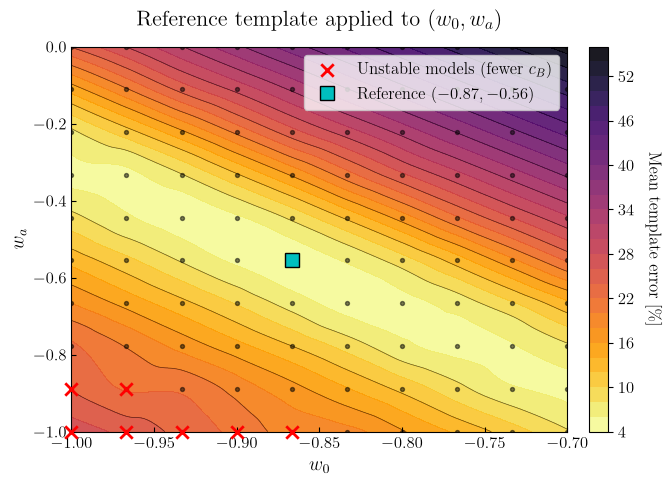

In [99]:
W0, WA = np.meshgrid(np.linspace(w0_arr.min(), w0_arr.max(), 150), np.linspace(wa_arr.min(), wa_arr.max(), 150))
Z_ref = griddata((w0_arr, wa_arr), ref_err_arr, (W0, WA), method='cubic')

fig, ax = plt.subplots(figsize=(7, 5))
contour = ax.contourf(W0, WA, Z_ref, levels=25, cmap='inferno_r', alpha=0.9)
ax.contour(W0, WA, Z_ref, levels=12, colors='k', linewidths=0.5, alpha=0.6)
ax.scatter(w0_arr, wa_arr, s=8, c='k', alpha=0.5)
mark_unstable(ax)
ax.plot(*ref, marker='s', color='c', markersize=10, markeredgecolor='k', linestyle='none',
        clip_on=False, zorder=6, label=fr'Reference $({ref[0]:.2f}, {ref[1]:.2f})$')

cbar = plt.colorbar(contour, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label(r'Mean template error [\%]', rotation=270, labelpad=20, fontsize=12)

ax.set_title(r'Reference template applied to ($w_0 , w_a$)', fontsize=16, pad=15)
ax.set_xlabel(r'$w_0$', fontsize=14)
ax.set_ylabel(r'$w_a$', fontsize=14)
ax.legend(loc='upper right')
ax.tick_params(axis='both', which='both', direction='in')

## Global template: coefficients linear in $w_0 + w_a$

Each coefficient is taken from the linear fits above, $c = \alpha + \beta\,(w_0 + w_a)$, so the background
enters the template through $w_0 + w_a$ (and through $k_B$, computed with each cosmology). The template
built this way is evaluated on every background, in the same $k$ range as the fits.

In [100]:
def global_template(spectra):
    """Template of a background with m, y0 = alpha + beta (w0 + wa)."""
    x_bg = spectra.w0 + spectra.wa
    coefficients = {p: {q: (alpha + beta * x_bg, np.nan) for q, (alpha, beta) in qs.items()}
                    for p, qs in global_coeffs.items()}
    return Template(MODEL, spectra.parametrization, coefficients, asdict(spectra.background))

global_err_arr = np.array([np.nanmean(list(global_template(sets[key]).errors(sets[key], k_min=K_MIN).values()))
                           for key in fits]) * 100

print(f"Global template error: {global_err_arr.min():.2f} - {global_err_arr.max():.2f} %  "
      f"(median {np.median(global_err_arr):.2f} %)")
print(f"For comparison - reference template: median {np.median(ref_err_arr):.2f} %, "
      f"fits per background: median {np.median(err_arr):.2f} %")

Global template error: 4.82 - 25.09 %  (median 7.87 %)
For comparison - reference template: median 17.08 %, fits per background: median 3.91 %


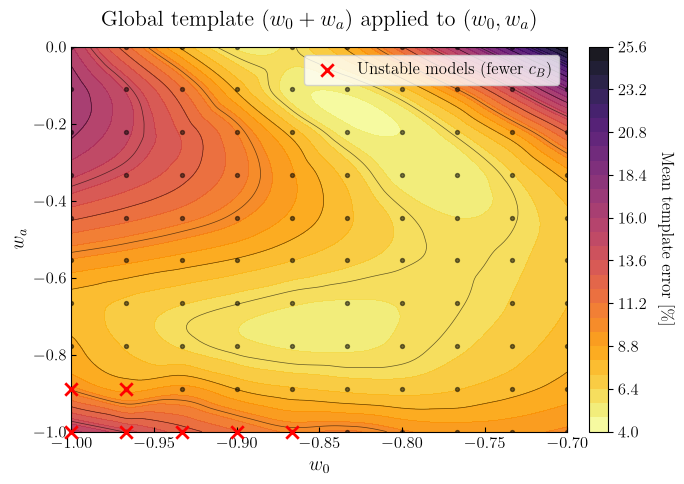

In [101]:
W0, WA = np.meshgrid(np.linspace(w0_arr.min(), w0_arr.max(), 150), np.linspace(wa_arr.min(), wa_arr.max(), 150))
Z_global = griddata((w0_arr, wa_arr), global_err_arr, (W0, WA), method='cubic')

fig, ax = plt.subplots(figsize=(7, 5))
contour = ax.contourf(W0, WA, Z_global, levels=25, cmap='inferno_r', alpha=0.9)
ax.contour(W0, WA, Z_global, levels=12, colors='k', linewidths=0.5, alpha=0.6)
ax.scatter(w0_arr, wa_arr, s=8, c='k', alpha=0.5)
mark_unstable(ax)

cbar = plt.colorbar(contour, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label(r'Mean template error [\%]', rotation=270, labelpad=20, fontsize=12)

ax.set_title(r'Global template ($w_0 + w_a$) applied to ($w_0 , w_a$)', fontsize=16, pad=15)
ax.set_xlabel(r'$w_0$', fontsize=14)
ax.set_ylabel(r'$w_a$', fontsize=14)
ax.legend(loc='upper right')
ax.tick_params(axis='both', which='both', direction='in')